# Market-Basket Analysis & Association Rules for Cross-Selling
## Emerging Wedding Planner (Pakistan) — Week 4 Assignment

> **Data disclosure:** the expected input (`wedding_planner_transactions.csv`) is synthetic/simulated educational data, not real client data. Keep this disclosure in your final submission.
>


### Business problem
An emerging wedding planner sells many separate services (photography, decoration, catering, DJ, ...). Most customers book only part of what they could. **Which services are bought together, and which bundles should the sales team recommend to increase revenue per booking?**

### Tools
Python 3 · pandas / numpy · **mlxtend** (`TransactionEncoder`, `fpgrowth`, `apriori`, `association_rules`) · matplotlib / seaborn · Jupyter. Every chart and table is also saved to the `outputs/` folder as evidence.






###  Five-line Learning Plan

1. Spend 30–45 minutes learning how basket encoding and FP-Growth identify frequently purchased combinations.
2. Practise interpreting support, confidence, and lift using a small example.
3. Apply FP-Growth to the wedding-planner transactions using minimum-support values of 1%, 2%, and 5%.
4. Validate the strongest rules on a separate time period and record which rules remain useful.
5. **Success target:** Produce at least five actionable cross-sell recommendations, each supported by rule metrics and second-period validation.

In [36]:
# Install once from a terminal:  pip install mlxtend seaborn pandas numpy matplotlib jupyter
print('Dependencies are listed in requirements.txt')

Dependencies are listed in requirements.txt


## 1. Setup and Configuration

In [37]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# ---------- Analysis parameters (change here if your instructor asks for different values) ----------
DATA_FILE   = "wedding_planner_transactions.csv"
MIN_SUPPORT = 0.02     # itemset must appear in at least 2% of baskets
MIN_CONF    = 0.30     # minimum confidence for rule generation
MIN_LIFT    = 1.20     # assignment requirement: keep rules with lift > 1.2
MIN_ITEM_SUPPORT = 0.02   # Step 3: a service in fewer than 2% of baskets is "too rare to matter"
TRIVIAL_CONF = 0.95       # Step 5a: rules with confidence >= 95% are near-certain (obvious) dependencies
MIN_IMPROVEMENT = 0.05   # Step 5b: a multi-service rule must beat its best simpler sub-rule by >= 5 confidence points
DISCOUNT     = 0.10       # Step 7: bundle discount given on the add-on service
import os; os.makedirs("outputs", exist_ok=True)

# Two different time periods (main analysis and second-period validation)
MAIN_START, MAIN_END = "2025-01-01", "2025-06-30"   # Period 1: Jan-Jun 2025  (main analysis)
VAL_START,  VAL_END  = "2025-07-01", "2025-12-31"   # Period 2: Jul-Dec 2025  (validation)
print("Parameters set.")

Parameters set.


## 2. Load and Validate the Data

In [38]:
df = pd.read_csv(DATA_FILE, parse_dates=["Transaction_Date"])
df.head(10)

,Transaction_ID,Transaction_Date,Customer_ID,Event_Type,Service,Quantity,Unit_Price_PKR,Line_Revenue_PKR
0,T00001,2025-01-01,C00001,Wedding,Bridal Makeup,1,36000,36000
1,T00001,2025-01-01,C00001,Wedding,Decoration,1,253000,253000
2,T00001,2025-01-01,C00001,Wedding,Drone Coverage,1,28000,28000
3,T00001,2025-01-01,C00001,Wedding,Floral Design,1,192000,192000
4,T00001,2025-01-01,C00001,Wedding,Invitation Cards,250,165,41250
5,T00001,2025-01-01,C00001,Wedding,Mehndi Artist,2,53000,106000
6,T00001,2025-01-01,C00001,Wedding,Photography,1,174000,174000
7,T00001,2025-01-01,C00001,Wedding,Videography,1,143000,143000
8,T00002,2025-01-01,C00002,Mehndi,Decoration,1,385000,385000
9,T00002,2025-01-01,C00002,Mehndi,Floral Design,1,116000,116000


In [39]:
g = df.groupby("Transaction_ID")
basket_size = g.size()

summary = {
    "Total rows (transaction lines)": len(df),
    "Unique Transaction_IDs (baskets)": df["Transaction_ID"].nunique(),
    "Unique customers": df["Customer_ID"].nunique(),
    "Unique services": df["Service"].nunique(),
    "Date range": f"{df['Transaction_Date'].min().date()} to {df['Transaction_Date'].max().date()}",
    "Min services per basket": int(basket_size.min()),
    "Max services per basket": int(basket_size.max()),
    "Mean services per basket": round(basket_size.mean(), 2),
    "Total revenue (PKR)": f"{df['Line_Revenue_PKR'].sum():,.0f}",
}
pd.Series(summary, name="Value").to_frame()

,Value
Total rows (transaction lines),35887
Unique Transaction_IDs (baskets),7500
Unique customers,6157
Unique services,20
Date range,2025-01-01 to 2025-12-31
Min services per basket,2
Max services per basket,8
Mean services per basket,4.780
Total revenue (PKR),"6,622,502,500"


In [40]:
# ---------- Data-quality checks (each must print True) ----------
checks = {
    ">= 7,000 unique baskets":                 df["Transaction_ID"].nunique() >= 7000,
    "No missing values":                        not df.isna().any().any(),
    "Every basket has >= 2 services":           basket_size.min() >= 2,
    "No duplicate (basket, service) records":   not df.duplicated(["Transaction_ID", "Service"]).any(),
    "All quantities > 0":                       (df["Quantity"] > 0).all(),
    "All unit prices > 0":                      (df["Unit_Price_PKR"] > 0).all(),
    "Line_Revenue = Quantity x Unit_Price":     (df["Quantity"] * df["Unit_Price_PKR"] == df["Line_Revenue_PKR"]).all(),
    "One date per basket":                      (g["Transaction_Date"].nunique() == 1).all(),
    "All dates inside 2025":                    df["Transaction_Date"].dt.year.eq(2025).all(),
}
pd.Series(checks, name="Passed").to_frame()

,Passed
">= 7,000 unique baskets",True
No missing values,True
Every basket has >= 2 services,True
"No duplicate (basket, service) records",True
All quantities > 0,True
All unit prices > 0,True
Line_Revenue = Quantity x Unit_Price,True
One date per basket,True
All dates inside 2025,True


## 3. Exploratory Data Analysis

### 3.1 Basket size and service popularity

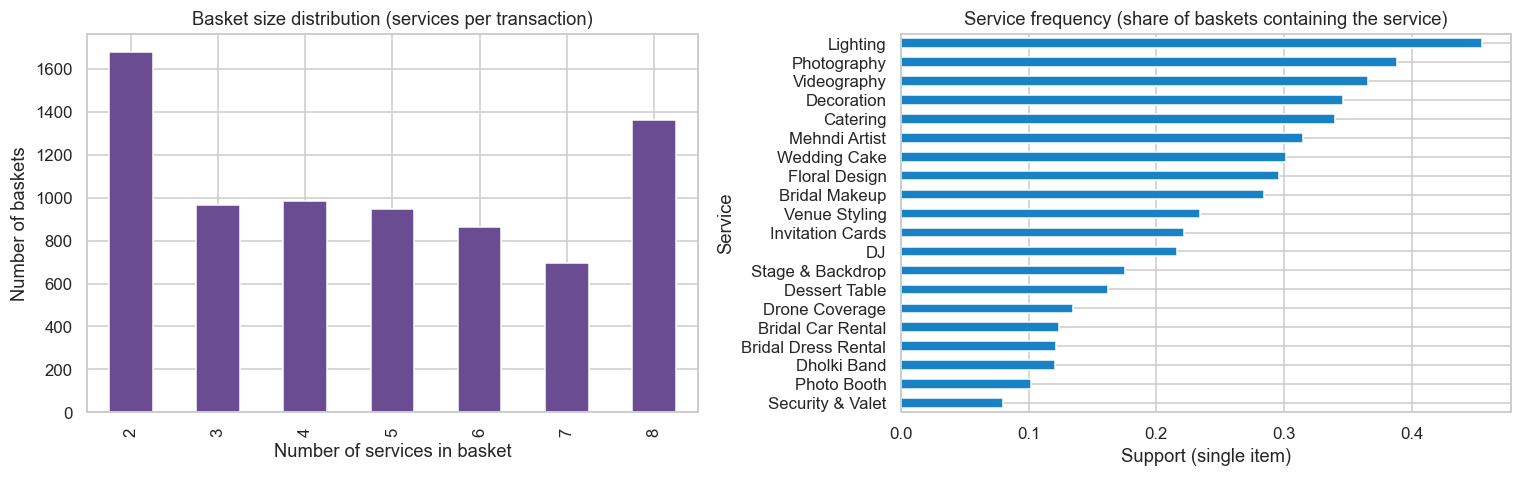

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

basket_size.value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#6a4c93")
ax[0].set_title("Basket size distribution (services per transaction)")
ax[0].set_xlabel("Number of services in basket"); ax[0].set_ylabel("Number of baskets")

popularity = (df.groupby("Service")["Transaction_ID"].nunique() / df["Transaction_ID"].nunique()).sort_values()
popularity.plot(kind="barh", ax=ax[1], color="#1982c4")
ax[1].set_title("Service frequency (share of baskets containing the service)")
ax[1].set_xlabel("Support (single item)")
plt.tight_layout(); plt.savefig("outputs/03a_basket_size_and_popularity.png", dpi=150, bbox_inches="tight"); plt.show()

### 3.2 Seasonality: transactions and revenue by month

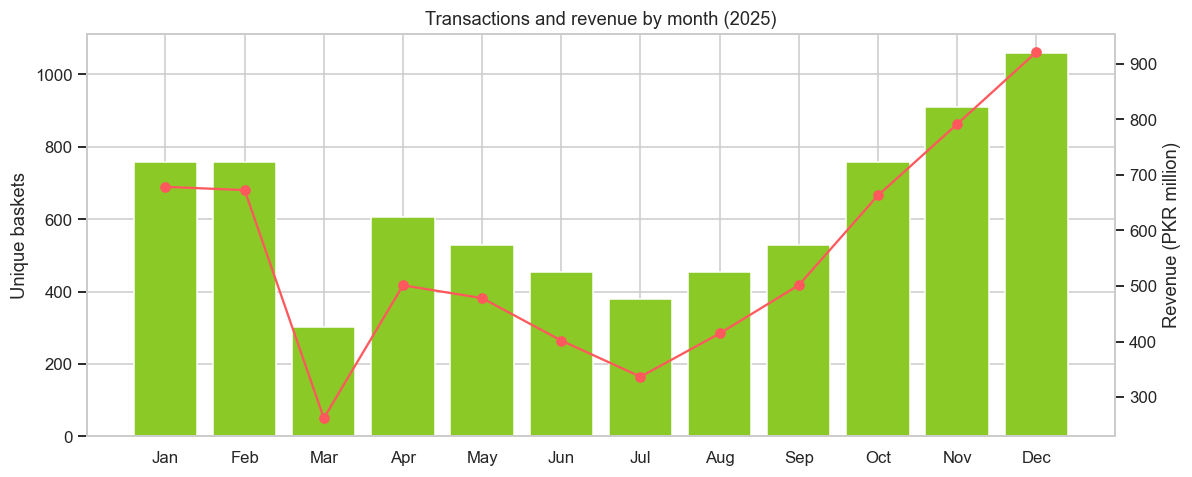

,Baskets,Revenue_PKR
Month,,
Jan,758,678486000
Feb,758,672653750
Mar,303,262022500
Apr,606,501200000
May,530,478123750
Jun,455,401715000
Jul,379,336675250
Aug,455,414541000
Sep,530,501552000


In [42]:
df["Month"] = df["Transaction_Date"].dt.month
monthly = df.groupby("Month").agg(Baskets=("Transaction_ID", "nunique"), Revenue_PKR=("Line_Revenue_PKR", "sum"))
monthly.index = pd.to_datetime(monthly.index, format="%m").strftime("%b")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(monthly.index, monthly["Baskets"], color="#8ac926")
ax.set_ylabel("Unique baskets"); ax.set_title("Transactions and revenue by month (2025)")
ax2 = ax.twinx(); ax2.plot(monthly.index, monthly["Revenue_PKR"] / 1e6, color="#ff595e", marker="o")
ax2.set_ylabel("Revenue (PKR million)"); ax2.grid(False)
plt.tight_layout(); plt.savefig("outputs/03b_monthly_seasonality.png", dpi=150, bbox_inches="tight"); plt.show()
monthly

### 3.3 Event types and revenue by service

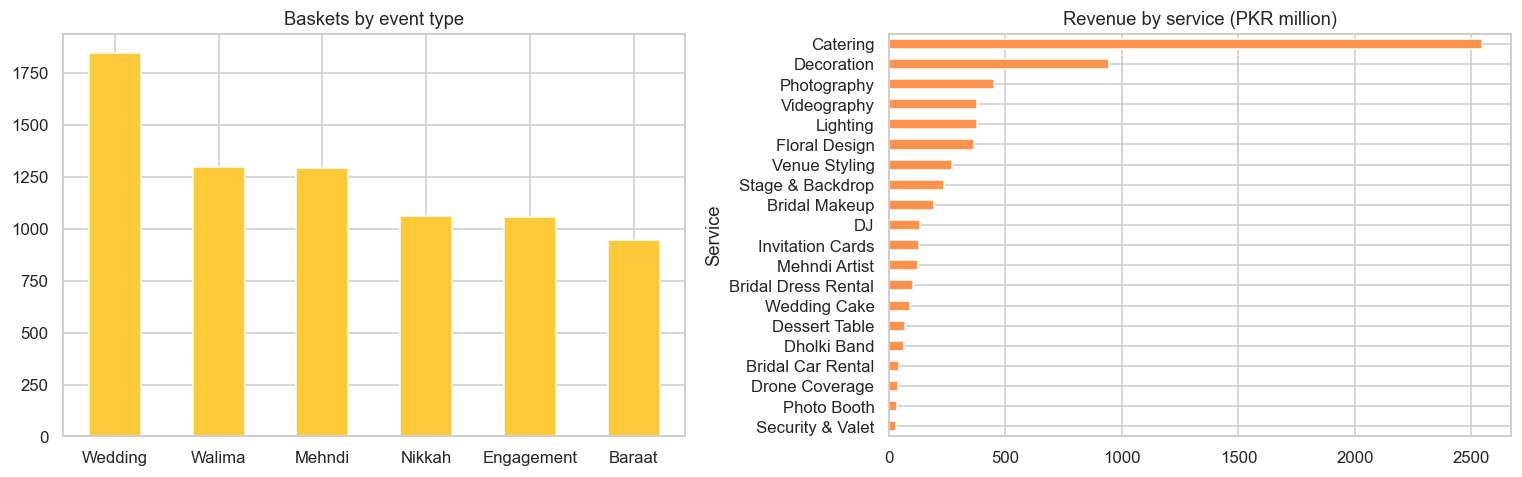

,Baskets,Avg_Unit_Price_PKR,Avg_Line_Revenue_PKR,Total_Revenue_PKR
Service,,,,
Catering,2551,"3,175.402","997,362.995",2544273000
Decoration,2598,"363,207.852","363,207.852",943614000
Photography,2915,"145,501.544","154,632.590",450754000
Videography,2746,"130,373.270","138,131.828",379310000
Lighting,3416,"110,476.581","110,476.581",377388000
Floral Design,2222,"164,635.014","164,635.014",365819000
Venue Styling,1755,"155,329.345","155,329.345",272603000
Stage & Backdrop,1314,"180,291.476","180,291.476",236903000
Bridal Makeup,2134,"73,046.392","91,164.246",194544500


In [43]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ev = g["Event_Type"].first().value_counts()
ev.plot(kind="bar", ax=ax[0], color="#ffca3a"); ax[0].set_title("Baskets by event type"); ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=0)

rev_service = df.groupby("Service")["Line_Revenue_PKR"].sum().sort_values() / 1e6
rev_service.plot(kind="barh", ax=ax[1], color="#ff924c"); ax[1].set_title("Revenue by service (PKR million)")
plt.tight_layout(); plt.savefig("outputs/03c_event_type_and_revenue.png", dpi=150, bbox_inches="tight"); plt.show()

service_table = df.groupby("Service").agg(
    Baskets=("Transaction_ID", "nunique"),
    Avg_Unit_Price_PKR=("Unit_Price_PKR", "mean"),
    Avg_Line_Revenue_PKR=("Line_Revenue_PKR", "mean"),
    Total_Revenue_PKR=("Line_Revenue_PKR", "sum"),
).sort_values("Total_Revenue_PKR", ascending=False)
service_table

In [44]:
basket_value = g["Line_Revenue_PKR"].sum()
print(f"Average basket value : PKR {basket_value.mean():,.0f}")
print(f"Median basket value  : PKR {basket_value.median():,.0f}")
print("\nAverage basket value by event type (PKR):")
print(df.groupby(["Event_Type"]).apply(lambda d: d.groupby("Transaction_ID")["Line_Revenue_PKR"].sum().mean()).sort_values(ascending=False).round(0).to_string())

Average basket value : PKR 883,000
Median basket value  : PKR 739,000

Average basket value by event type (PKR):
Event_Type
Walima       1,168,346.000
Wedding        961,972.000
Baraat         916,779.000
Mehndi         786,683.000
Engagement     723,982.000
Nikkah         641,346.000


## 4. Define the Two Time Periods

The assignment asks for rules to be checked on **two different time periods**:

| Role | Period | Purpose |
|---|---|---|
| **Main analysis** | Jan – Jun 2025 | Discover the rules |
| **Second-period validation** | Jul – Dec 2025 | Check that the same rules still hold on unseen baskets |

Rules that hold in both periods are *stable* and safer to turn into sales actions.

In [45]:
def in_period(d, start, end):
    return d[(d["Transaction_Date"] >= start) & (d["Transaction_Date"] <= end)]

df_main = in_period(df, MAIN_START, MAIN_END)
df_val  = in_period(df, VAL_START,  VAL_END)

pd.DataFrame({
    "Period": ["Main (Jan-Jun)", "Validation (Jul-Dec)"],
    "Baskets": [df_main["Transaction_ID"].nunique(), df_val["Transaction_ID"].nunique()],
    "Rows": [len(df_main), len(df_val)],
    "Revenue_PKR": [df_main["Line_Revenue_PKR"].sum(), df_val["Line_Revenue_PKR"].sum()],
})

,Period,Baskets,Rows,Revenue_PKR
0,Main (Jan-Jun),3410,16188,2994201000
1,Validation (Jul-Dec),4090,19699,3628301500


## 5. Build the Basket Matrix (one-hot encoding) and Remove Rare Items — Step 3

`mlxtend` needs one row per basket and one Boolean column per service.

In [46]:
def make_onehot(d):
    baskets = d.groupby("Transaction_ID")["Service"].apply(list)
    te = TransactionEncoder()
    arr = te.fit(baskets).transform(baskets)
    return pd.DataFrame(arr, columns=te.columns_, index=baskets.index)

basket_all  = make_onehot(df)
basket_main = make_onehot(df_main)
basket_val  = make_onehot(df_val)

print("Full year  :", basket_all.shape)
print("Main period:", basket_main.shape)
print("Validation :", basket_val.shape)
basket_main.head()

Full year  : (7500, 20)
Main period: (3410, 20)
Validation : (4090, 20)


,Bridal Car Rental,Bridal Dress Rental,Bridal Makeup,Catering,DJ,Decoration,Dessert Table,Dholki Band,Drone Coverage,Floral Design,Invitation Cards,Lighting,Mehndi Artist,Photo Booth,Photography,Security & Valet,Stage & Backdrop,Venue Styling,Videography,Wedding Cake
Transaction_ID,,,,,,,,,,,,,,,,,,,,
T00001,False,False,True,False,False,True,False,False,True,True,True,False,True,False,True,False,False,False,True,False
T00002,False,False,False,False,False,True,False,False,False,True,False,True,True,False,False,False,False,False,False,False
T00003,False,False,False,False,True,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False
T00004,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False
T00005,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,True,False,True


### Step 3 — Item frequencies and removal of rare items
A service that appears in fewer than `MIN_ITEM_SUPPORT` (2 %) of baskets cannot form reliable rules, so it would be removed. The chart shows every service's share of baskets; any bar left of the dashed line is removed.

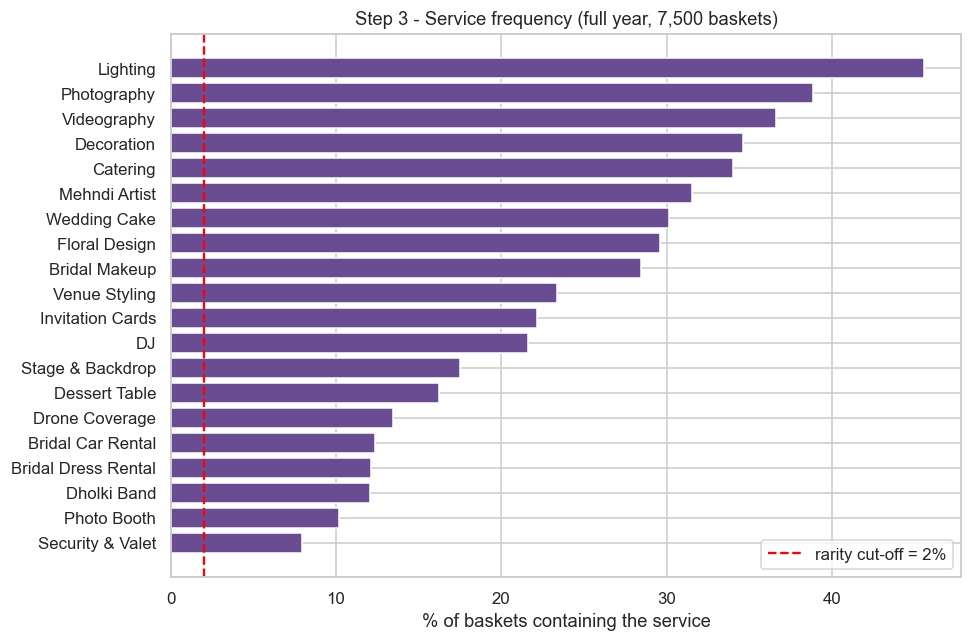

Rarest service : Security & Valet (8.0% of baskets)
Most common    : Lighting (45.5% of baskets)
No service is below the cut-off, so no service is removed (all remain frequent enough to analyse).
Services kept: 20


In [47]:
item_support = basket_all.mean().sort_values()
rare_items = item_support[item_support < MIN_ITEM_SUPPORT].index.tolist()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(item_support.index, item_support * 100, color=["#d62828" if s < MIN_ITEM_SUPPORT else "#6a4c93" for s in item_support])
ax.axvline(MIN_ITEM_SUPPORT * 100, color="red", ls="--", label=f"rarity cut-off = {MIN_ITEM_SUPPORT:.0%}")
ax.set_xlabel("% of baskets containing the service"); ax.set_title("Step 3 - Service frequency (full year, 7,500 baskets)")
ax.legend(); plt.tight_layout(); plt.savefig("outputs/05_item_frequency_rare_cutoff.png", dpi=150, bbox_inches="tight"); plt.show()

print(f"Rarest service : {item_support.index[0]} ({item_support.iloc[0]:.1%} of baskets)")
print(f"Most common    : {item_support.index[-1]} ({item_support.iloc[-1]:.1%} of baskets)")
if rare_items:
    basket_all, basket_main, basket_val = [b.drop(columns=rare_items) for b in (basket_all, basket_main, basket_val)]
    print("Removed as too rare:", rare_items)
else:
    print("No service is below the cut-off, so no service is removed (all remain frequent enough to analyse).")
print("Services kept:", basket_all.shape[1])
item_support.rename("support").to_frame().to_csv("outputs/05_item_support.csv")

**Interpretation (Step 3):** Use the output and frequency chart directly above after rerunning the notebook to report the rarest service, most common service, and how many items were removed. Do not copy figures from an earlier run if they do not match your current CSV.

## 6. Frequent Itemsets — FP-Growth (main period)

**Support** of an itemset = share of baskets that contain it:
`support(A) = baskets containing A / total baskets`

In [48]:
freq_main = fpgrowth(basket_main, min_support=MIN_SUPPORT, use_colnames=True)
freq_main["size"] = freq_main["itemsets"].apply(len)
freq_main["itemset"] = freq_main["itemsets"].apply(lambda s: " + ".join(sorted(s)))

print(f"Frequent itemsets found (min_support = {MIN_SUPPORT:.0%}): {len(freq_main)}")
print(freq_main.groupby("size").size().rename("count").to_frame().T.to_string())
freq_main.sort_values("support", ascending=False)[["itemset", "size", "support"]].head(15).reset_index(drop=True)

Frequent itemsets found (min_support = 2%): 579
size    1    2    3    4   5
count  20  161  275  111  12


,itemset,size,support
0,Lighting,1,0.458
1,Photography,1,0.391
2,Videography,1,0.373
3,Decoration,1,0.349
4,Catering,1,0.334
5,Mehndi Artist,1,0.310
6,Wedding Cake,1,0.300
7,Floral Design,1,0.298
8,Photography + Videography,2,0.285
9,Bridal Makeup,1,0.276


### Cross-check: Apriori must return the same itemsets as FP-Growth

In [49]:
ap_main = apriori(basket_main, min_support=MIN_SUPPORT, use_colnames=True)
same = set(map(frozenset, ap_main["itemsets"])) == set(map(frozenset, freq_main["itemsets"]))
print("Apriori and FP-Growth return identical itemsets:", same)

Apriori and FP-Growth return identical itemsets: True


## 7. Association Rules (main period) — Steps 4 and 5

For a rule **A → B**:

- **Support** = P(A and B)
- **Confidence** = P(B | A) = support(A,B) / support(A)
- **Lift** = confidence / support(B)  — lift > 1 means A and B occur together more often than if they were independent. We keep **lift > 1.2**.

These metrics are *calculated by mlxtend*; the dataset contains no pre-computed support/confidence/lift.

In [50]:
from itertools import combinations
def label(s): return ", ".join(sorted(s))

def remove_redundant(rules, freq, min_improvement=MIN_IMPROVEMENT):
    """Drop rule X -> c (|X| >= 2) when a simpler rule S -> c (S a subset of X) is almost as confident:
    the extra services in X add no real information, so the bigger rule is redundant."""
    sup = {frozenset(i): v for i, v in zip(freq["itemsets"], freq["support"])}
    keep = []
    for a, c, conf in zip(rules["antecedents"], rules["consequents"], rules["confidence"]):
        best = 0.0
        for k in range(1, len(a)):
            for S in combinations(a, k):
                S = frozenset(S)
                if S in sup and (S | c) in sup: best = max(best, sup[S | c] / sup[S])
        keep.append(len(a) == 1 or conf - best >= min_improvement)
    return rules[keep]

def mine_rules(onehot, min_support=MIN_SUPPORT, min_conf=MIN_CONF, min_lift=MIN_LIFT, drop_trivial=True):
    freq = fpgrowth(onehot, min_support=min_support, use_colnames=True)
    rules = association_rules(freq, metric="confidence", min_threshold=min_conf)
    rules = rules[rules["lift"] > min_lift].copy()
    if drop_trivial:                       # Step 5: remove obvious / redundant rules
        rules = rules[rules["confidence"] < TRIVIAL_CONF].copy()   # 5a near-certain
        rules = remove_redundant(rules, freq)                       # 5b redundant multi-service rules
    rules["antecedent"] = rules["antecedents"].apply(label)
    rules["consequent"] = rules["consequents"].apply(label)
    rules["rule"] = rules["antecedent"] + "  →  " + rules["consequent"]
    rules["n_ante"] = rules["antecedents"].apply(len)
    rules["n_cons"] = rules["consequents"].apply(len)
    cols = ["rule", "antecedent", "consequent", "n_ante", "n_cons", "antecedent support", "consequent support",
            "support", "confidence", "lift", "leverage", "conviction"]
    return rules[cols].sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)

rules_main = mine_rules(basket_main)
print(f"Rules with confidence >= {MIN_CONF}, lift > {MIN_LIFT} and not trivial (conf < {TRIVIAL_CONF:.0%}): {len(rules_main)}")
rules_main_1to1 = rules_main[(rules_main.n_ante == 1) & (rules_main.n_cons == 1)].reset_index(drop=True)
print(f"  of which one-service → one-service rules: {len(rules_main_1to1)}")
rules_main_1to1[["rule", "support", "confidence", "lift", "leverage", "conviction"]].head(30)

Rules with confidence >= 0.3, lift > 1.2 and not trivial (conf < 95%): 218
  of which one-service → one-service rules: 44


,rule,support,confidence,lift,leverage,conviction
0,Dessert Table → Wedding Cake,0.117,0.772,2.574,0.072,3.073
1,Wedding Cake → Dessert Table,0.117,0.391,2.574,0.072,1.393
2,Bridal Dress Rental → Bridal Makeup,0.084,0.707,2.563,0.051,2.473
3,Bridal Makeup → Bridal Dress Rental,0.084,0.303,2.563,0.051,1.265
4,Stage & Backdrop → Decoration,0.132,0.781,2.241,0.073,2.977
5,Decoration → Stage & Backdrop,0.132,0.378,2.241,0.073,1.337
6,Venue Styling → Decoration,0.176,0.761,2.184,0.095,2.730
7,Decoration → Venue Styling,0.176,0.505,2.184,0.095,1.552
8,Bridal Makeup → Mehndi Artist,0.184,0.668,2.154,0.099,2.080
9,Mehndi Artist → Bridal Makeup,0.184,0.595,2.154,0.099,1.786


### 7.1 Step 4 — FP-Growth with three minimum-support values
The same data is mined at 1 %, 2 % and 5 % minimum support and the number of itemsets and rules is compared.

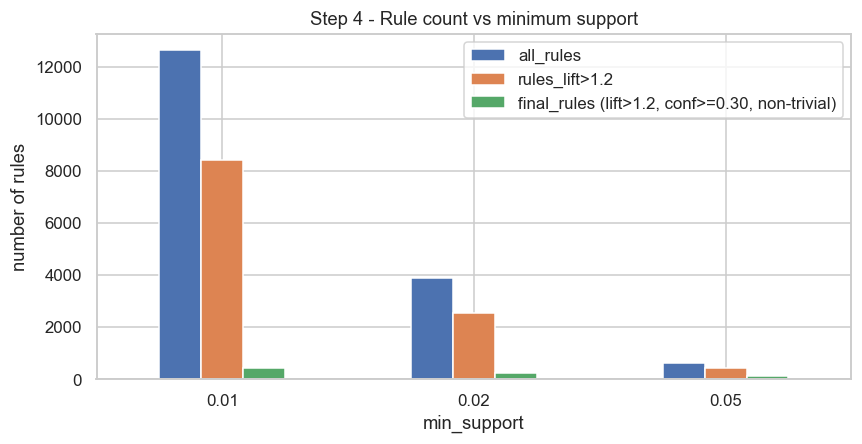

,min_support,frequent_itemsets,all_rules,rules_lift>1.2,"final_rules (lift>1.2, conf>=0.30, non-trivial)",final_one_to_one
0,0.010,1257,12626,8408,408,44
1,0.020,579,3886,2548,218,44
2,0.050,169,630,410,104,41


In [51]:
rows = []
for ms in [0.01, 0.02, 0.05]:
    f = fpgrowth(basket_main, min_support=ms, use_colnames=True)
    all_r = association_rules(f, metric="confidence", min_threshold=0)
    r_final = mine_rules(basket_main, min_support=ms)
    rows.append({"min_support": ms, "frequent_itemsets": len(f), "all_rules": len(all_r),
                 "rules_lift>1.2": int((all_r.lift > MIN_LIFT).sum()),
                 "final_rules (lift>1.2, conf>=0.30, non-trivial)": len(r_final),
                 "final_one_to_one": int(((r_final.n_ante == 1) & (r_final.n_cons == 1)).sum())})
support_cmp = pd.DataFrame(rows)
support_cmp.to_csv("outputs/07_support_comparison.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
support_cmp.set_index("min_support")[["all_rules", "rules_lift>1.2", "final_rules (lift>1.2, conf>=0.30, non-trivial)"]].plot.bar(ax=ax, rot=0)
ax.set_ylabel("number of rules"); ax.set_title("Step 4 - Rule count vs minimum support")
plt.tight_layout(); plt.savefig("outputs/07c_support_vs_rule_count.png", dpi=150, bbox_inches="tight"); plt.show()
support_cmp

**Decision (Step 4):** Compare the three rows produced by the cell above. Choose the support threshold that gives a useful number of rules without losing too many meaningful one-to-one pairs. Explain the decision using the freshly computed counts; do not rely on previously saved figures.

### 7.2 Step 5 — Lift > 1.2 and removal of obvious / trivial rules
Two kinds of trivial rule are removed after the lift filter:
* **5a Near-certain rules** (confidence ≥ 95 %): add-ons that cannot really be bought without the main service. True, but not useful.
* **5b Redundant multi-service rules**: a rule like *A + B → C* is redundant when the simpler *A → C* is already almost as confident (less than 5 confidence points of improvement). The extra service B adds nothing a sales agent could use.

Mirror pairs (A → B and B → A) are kept in the rule table, but Section 10 keeps only the sensible sales direction for each pair.

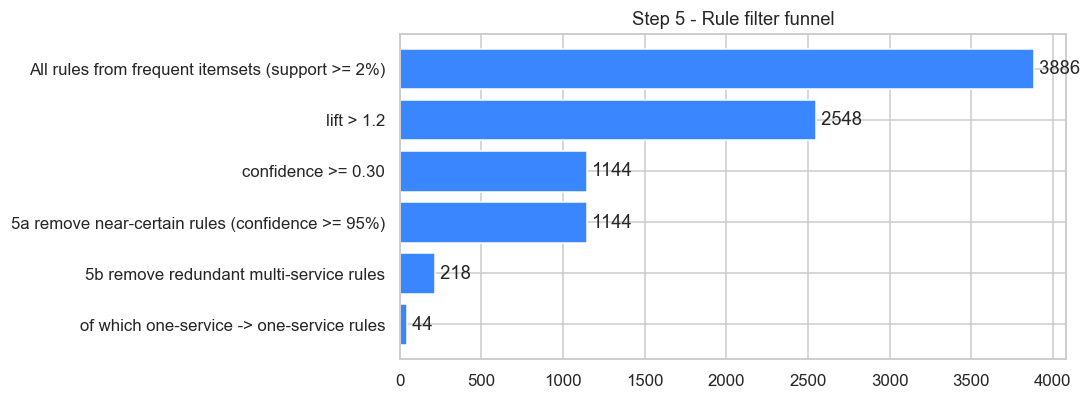

,Filter,Rules remaining
0,All rules from frequent itemsets (support >= 2%),3886
1,lift > 1.2,2548
2,confidence >= 0.30,1144
3,5a remove near-certain rules (confidence >= 95%),1144
4,5b remove redundant multi-service rules,218
5,of which one-service -> one-service rules,44


Highest confidence of any rule in the data: 92.4%  ->  near-certain rules removed: 0
Redundant multi-service rules removed: 926

Examples of redundant rules that were removed (highest lift first):


,rule,confidence,lift
0,"Decoration, Lighting, Wedding Cake → Caterin...",0.319,4.997
1,"Lighting, Photography, Wedding Cake → Cateri...",0.556,4.784
2,"Lighting, Videography, Wedding Cake → Cateri...",0.586,4.737
3,"Catering, Lighting, Videography → Photograph...",0.503,4.635
4,"Decoration, Lighting, Videography → Photogra...",0.356,4.466
5,"Catering, Lighting, Photography → Videograph...",0.452,4.443
6,"Decoration, Lighting, Wedding Cake → Caterin...",0.380,4.272
7,"Decoration, Lighting, Videography → Floral D...",0.459,4.234


In [52]:
freq_s = fpgrowth(basket_main, min_support=MIN_SUPPORT, use_colnames=True)
all_r = association_rules(freq_s, metric="confidence", min_threshold=0)
r_lift = all_r[all_r.lift > MIN_LIFT]
r_conf = r_lift[r_lift.confidence >= MIN_CONF]
near_certain = r_conf[r_conf.confidence >= TRIVIAL_CONF]
r_nc = r_conf[r_conf.confidence < TRIVIAL_CONF]
r_clean = remove_redundant(r_nc, freq_s)
redundant = r_nc.drop(r_clean.index)
r_one = r_clean[(r_clean.antecedents.apply(len) == 1) & (r_clean.consequents.apply(len) == 1)]
assert len(r_clean) == len(rules_main)
funnel = pd.DataFrame({"Filter": ["All rules from frequent itemsets (support >= 2%)", "lift > 1.2", "confidence >= 0.30",
                                  "5a remove near-certain rules (confidence >= 95%)", "5b remove redundant multi-service rules",
                                  "of which one-service -> one-service rules"],
                       "Rules remaining": [len(all_r), len(r_lift), len(r_conf), len(r_nc), len(r_clean), len(r_one)]})
funnel.to_csv("outputs/07_rule_filter_funnel.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(funnel.Filter[::-1], funnel["Rules remaining"][::-1], color="#3a86ff"); ax.set_title("Step 5 - Rule filter funnel")
for i, v in enumerate(funnel["Rules remaining"][::-1]): ax.text(v, i, f" {v}", va="center")
plt.tight_layout(); plt.savefig("outputs/07d_rule_filter_funnel.png", dpi=150, bbox_inches="tight"); plt.show()
display(funnel)
print(f"Highest confidence of any rule in the data: {r_conf.confidence.max():.1%}  ->  near-certain rules removed: {len(near_certain)}")
print(f"Redundant multi-service rules removed: {len(redundant)}")

def lab(df): return df.antecedents.apply(label) + "  →  " + df.consequents.apply(label)
ex = redundant.assign(rule=lab(redundant)).sort_values("lift", ascending=False)
ex[["rule", "support", "confidence", "lift"]].to_csv("outputs/07_removed_redundant_rules.csv", index=False)
print("\nExamples of redundant rules that were removed (highest lift first):")
ex[["rule", "confidence", "lift"]].head(8).reset_index(drop=True)

**Interpretation (Step 5):** Report the freshly computed rule-filter funnel above. Explain how many rules remain after lift, confidence, near-certain-rule, and redundancy filters. If a filter removes zero rules, say so explicitly rather than implying it helped.

### 7.1 Visualising the rules

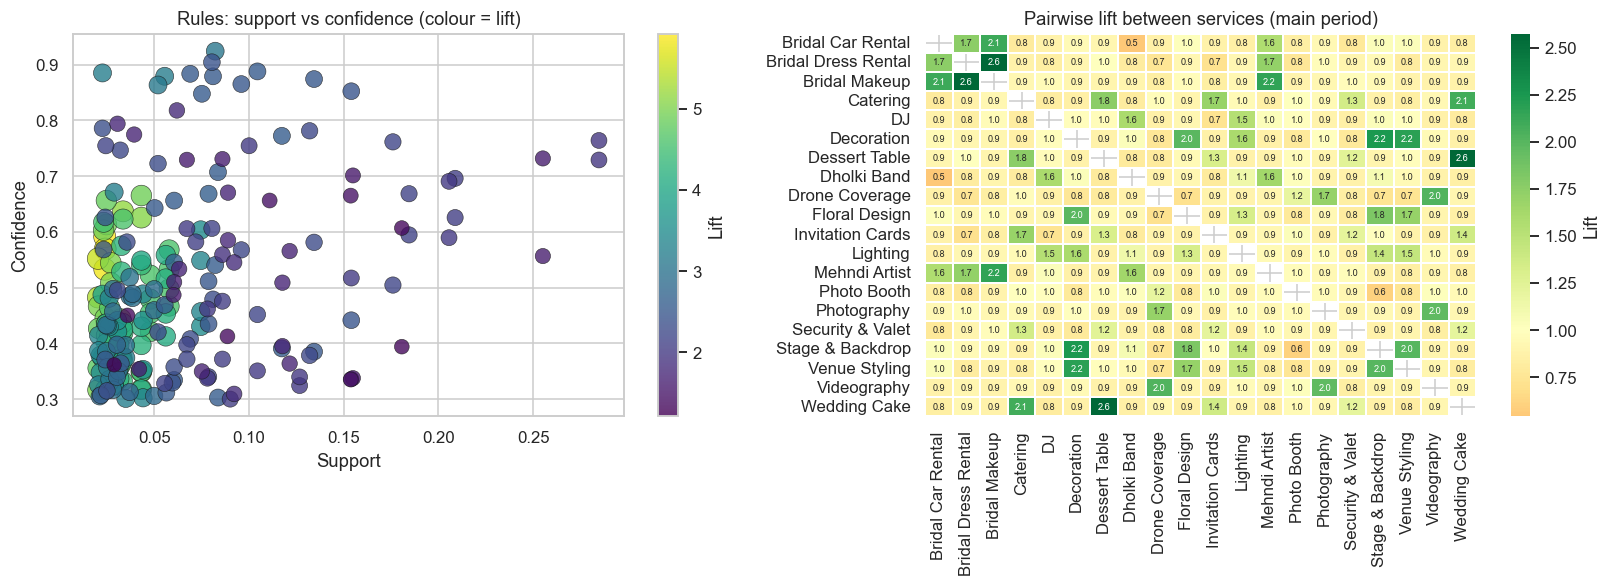

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

sc = ax[0].scatter(rules_main["support"], rules_main["confidence"], c=rules_main["lift"], cmap="viridis",
                   s=60 + 25 * rules_main["lift"], alpha=0.8, edgecolor="k", linewidth=0.4)
plt.colorbar(sc, ax=ax[0], label="Lift")
ax[0].set_xlabel("Support"); ax[0].set_ylabel("Confidence"); ax[0].set_title("Rules: support vs confidence (colour = lift)")

# pairwise lift heat-map (all service pairs)
sup = basket_main.mean()
co = basket_main.T.astype(int).dot(basket_main.astype(int)) / len(basket_main)
lift_vals = co.to_numpy(copy=True) / np.outer(sup.to_numpy(), sup.to_numpy())
np.fill_diagonal(lift_vals, np.nan)
lift_matrix = pd.DataFrame(lift_vals, index=co.index, columns=co.columns)
sns.heatmap(lift_matrix, ax=ax[1], cmap="RdYlGn", center=1, annot=True, fmt=".1f", annot_kws={"size": 6},
            cbar_kws={"label": "Lift"}, linewidths=0.3)
ax[1].set_title("Pairwise lift between services (main period)")
plt.tight_layout(); plt.savefig("outputs/07a_rules_scatter_and_lift_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

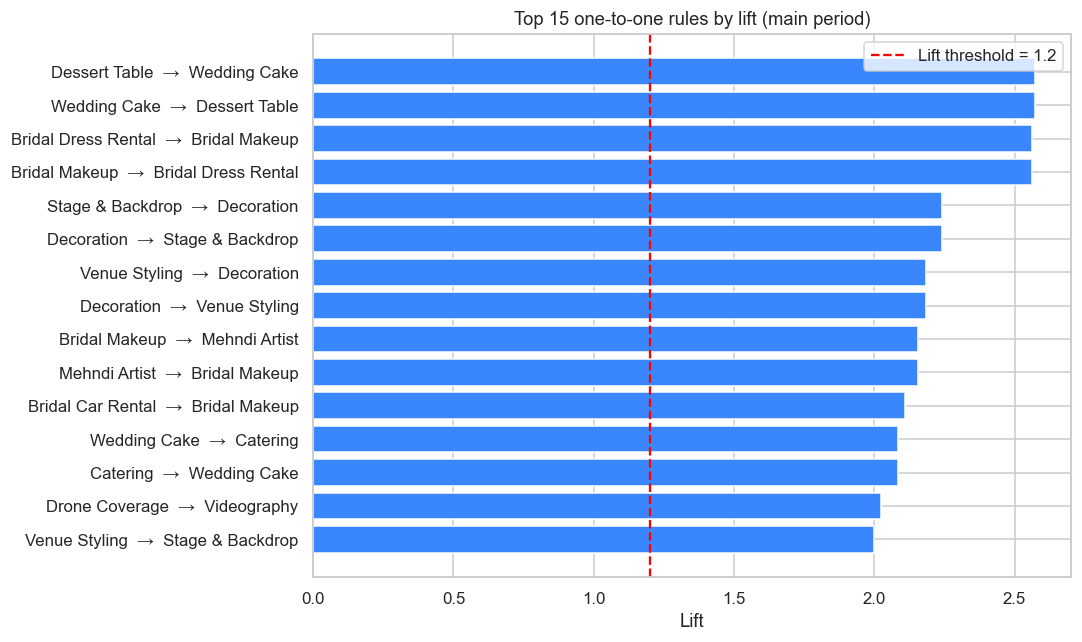

In [54]:
top = rules_main_1to1.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["rule"], top["lift"], color="#3a86ff")
ax.axvline(MIN_LIFT, color="red", ls="--", label=f"Lift threshold = {MIN_LIFT}")
ax.set_xlabel("Lift"); ax.set_title("Top 15 one-to-one rules by lift (main period)"); ax.legend()
plt.tight_layout(); plt.savefig("outputs/07b_top15_rules_by_lift.png", dpi=150, bbox_inches="tight"); plt.show()

### 7.2 Larger bundles (rules with 2+ services on the left side)

In [55]:
multi = rules_main[rules_main.n_ante >= 2].sort_values(["lift", "confidence"], ascending=False)
multi[["rule", "support", "confidence", "lift"]].head(15).reset_index(drop=True)

,rule,support,confidence,lift
0,"Bridal Dress Rental, Videography → Bridal Ma...",0.024,0.591,5.930
1,"Bridal Dress Rental, Photography → Bridal Ma...",0.024,0.533,5.824
2,"Floral Design, Lighting, Wedding Cake → Cate...",0.024,0.569,5.711
3,"Lighting, Venue Styling, Wedding Cake → Cate...",0.020,0.552,5.536
4,"Catering, Lighting, Venue Styling → Decorati...",0.020,0.483,5.360
5,"Lighting, Photography, Venue Styling → Decor...",0.033,0.637,5.159
6,"Decoration, Videography → Floral Design, Lig...",0.043,0.349,5.067
7,"Floral Design, Lighting, Photography → Decor...",0.043,0.626,5.067
8,"Dessert Table, Videography → Photography, We...",0.027,0.544,5.017
9,"Bridal Makeup, Floral Design, Lighting → Dec...",0.021,0.467,5.004


## 8. Second-Period Validation (Jul – Dec) — Step 8

The **same** parameters are applied to the validation period. A rule is **validated** when it again reaches **lift > 1.2** and **confidence ≥ 0.30** on baskets the main analysis never saw.

In [56]:
rules_val = mine_rules(basket_val)
print(f"Rules found in validation period: {len(rules_val)}")

cmp = rules_main.merge(rules_val[["rule", "support", "confidence", "lift"]], on="rule", how="left",
                       suffixes=("_main", "_val"))
cmp["validated"] = cmp["lift_val"].notna()
cmp["lift_change_%"] = (cmp["lift_val"] / cmp["lift_main"] - 1) * 100
cmp["conf_change_pts"] = (cmp["confidence_val"] - cmp["confidence_main"]) * 100

print(f"Main-period rules that are validated in the second period: {cmp['validated'].sum()} of {len(cmp)} "
      f"({cmp['validated'].mean():.0%})")

cmp_1to1 = cmp[(cmp.n_ante == 1) & (cmp.n_cons == 1)].copy()
cmp_1to1[["rule", "support_main", "confidence_main", "lift_main",
          "support_val", "confidence_val", "lift_val", "validated"]].head(30).reset_index(drop=True)

Rules found in validation period: 243
Main-period rules that are validated in the second period: 190 of 218 (87%)


,rule,support_main,confidence_main,lift_main,support_val,confidence_val,lift_val,validated
0,Dessert Table → Wedding Cake,0.117,0.772,2.574,0.126,0.740,2.442,True
1,Wedding Cake → Dessert Table,0.117,0.391,2.574,0.126,0.417,2.442,True
2,Bridal Dress Rental → Bridal Makeup,0.084,0.707,2.563,0.088,0.709,2.430,True
3,Bridal Makeup → Bridal Dress Rental,0.084,0.303,2.563,0.088,0.300,2.430,True
4,Stage & Backdrop → Decoration,0.132,0.781,2.241,0.137,0.762,2.211,True
5,Decoration → Stage & Backdrop,0.132,0.378,2.241,0.137,0.399,2.211,True
6,Venue Styling → Decoration,0.176,0.761,2.184,0.183,0.776,2.251,True
7,Decoration → Venue Styling,0.176,0.505,2.184,0.183,0.532,2.251,True
8,Bridal Makeup → Mehndi Artist,0.184,0.668,2.154,0.197,0.675,2.113,True
9,Mehndi Artist → Bridal Makeup,0.184,0.595,2.154,0.197,0.616,2.113,True


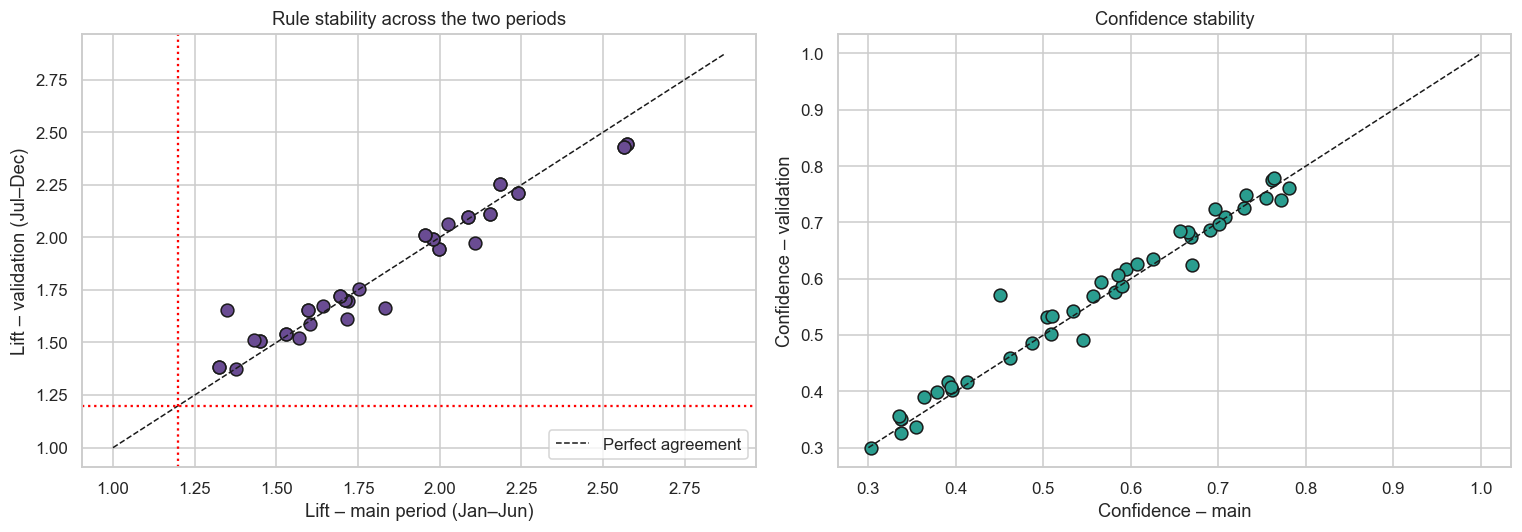

Correlation of lift between periods      : 0.977
Correlation of confidence between periods: 0.983
Mean absolute lift change (%)            : 3.2


In [57]:
v = cmp_1to1[cmp_1to1.validated]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(v["lift_main"], v["lift_val"], s=70, color="#6a4c93", edgecolor="k")
lim = [1, max(v["lift_main"].max(), v["lift_val"].max()) + 0.3]
ax[0].plot(lim, lim, "k--", lw=1, label="Perfect agreement")
ax[0].axhline(MIN_LIFT, color="red", ls=":"); ax[0].axvline(MIN_LIFT, color="red", ls=":")
ax[0].set_xlabel("Lift – main period (Jan–Jun)"); ax[0].set_ylabel("Lift – validation (Jul–Dec)")
ax[0].set_title("Rule stability across the two periods"); ax[0].legend()

ax[1].scatter(v["confidence_main"], v["confidence_val"], s=70, color="#2a9d8f", edgecolor="k")
ax[1].plot([0.3, 1], [0.3, 1], "k--", lw=1)
ax[1].set_xlabel("Confidence – main"); ax[1].set_ylabel("Confidence – validation")
ax[1].set_title("Confidence stability")
plt.tight_layout(); plt.savefig("outputs/08a_period_stability_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

print("Correlation of lift between periods      :", round(v["lift_main"].corr(v["lift_val"]), 3))
print("Correlation of confidence between periods:", round(v["confidence_main"].corr(v["confidence_val"]), 3))
print("Mean absolute lift change (%)            :", round(v["lift_change_%"].abs().mean(), 1))

### 8.2 Strict out-of-time test — rules are fixed on Jan–Jun and re-measured on Jul–Dec
Section 8 re-mines the second period. This stricter test **freezes** every Jan–Jun rule and measures its support, confidence and lift directly on the Jul–Dec baskets, so a rule cannot pass just because the miner re-discovered something similar. A rule *holds* if its holdout lift is still above 1.2.

ALL rules      : 217 of 218 hold on the frozen Jul-Dec test (100%)
One-to-one     : 43 of 44 hold (98%)
TOP-10 by lift : 10 of 10 hold | mean |lift change| = 3.3%
Rules that failed: 1


,rule,confidence,lift,confidence_holdout,lift_holdout
217,Security & Valet → Wedding Cake,0.362,1.205,0.361,1.191


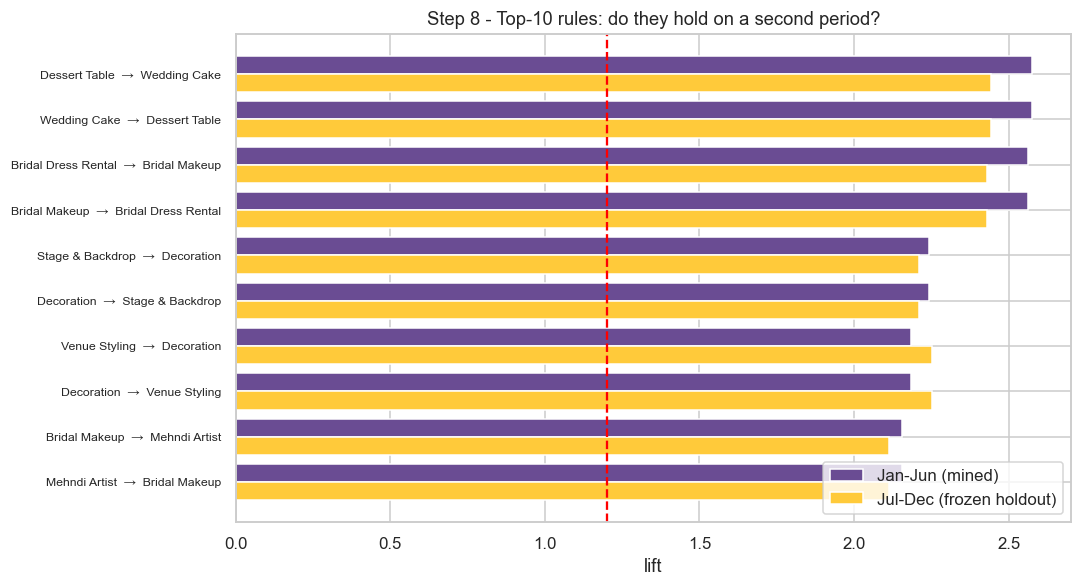

,rule,confidence,lift,confidence_holdout,lift_holdout,holds
0,Dessert Table → Wedding Cake,0.772,2.574,0.740,2.442,True
1,Wedding Cake → Dessert Table,0.391,2.574,0.417,2.442,True
2,Bridal Dress Rental → Bridal Makeup,0.707,2.563,0.709,2.430,True
3,Bridal Makeup → Bridal Dress Rental,0.303,2.563,0.300,2.430,True
4,Stage & Backdrop → Decoration,0.781,2.241,0.762,2.211,True
5,Decoration → Stage & Backdrop,0.378,2.241,0.399,2.211,True
6,Venue Styling → Decoration,0.761,2.184,0.776,2.251,True
7,Decoration → Venue Styling,0.505,2.184,0.532,2.251,True
8,Bridal Makeup → Mehndi Artist,0.668,2.154,0.675,2.113,True
9,Mehndi Artist → Bridal Makeup,0.595,2.154,0.616,2.113,True


In [58]:
def eval_on(rules, onehot):
    out = []
    for a, c in zip(rules["antecedent"], rules["consequent"]):
        A, C_ = a.split(", "), c.split(", ")
        ma, mc = onehot[A].all(axis=1), onehot[C_].all(axis=1)
        sup = (ma & mc).mean(); conf = sup / ma.mean() if ma.mean() else np.nan
        out.append((sup, conf, conf / mc.mean() if mc.mean() else np.nan))
    return pd.DataFrame(out, columns=["support_holdout", "confidence_holdout", "lift_holdout"], index=rules.index)

strict = pd.concat([rules_main[["rule", "n_ante", "n_cons", "support", "confidence", "lift"]], eval_on(rules_main, basket_val)], axis=1)
strict["holds"] = strict.lift_holdout > MIN_LIFT
strict["lift_change_%"] = (strict.lift_holdout / strict.lift - 1) * 100
strict.round(3).to_csv("outputs/08_rule_table_jan_jun_vs_jul_dec.csv", index=False)
cmp.round(3).drop(columns=["antecedents", "consequents"], errors="ignore").to_csv("outputs/08_rule_table_with_revalidation.csv", index=False)

one = strict[(strict.n_ante == 1) & (strict.n_cons == 1)].sort_values("lift", ascending=False)
print(f"ALL rules      : {strict.holds.sum()} of {len(strict)} hold on the frozen Jul-Dec test ({strict.holds.mean():.0%})")
print(f"One-to-one     : {one.holds.sum()} of {len(one)} hold ({one.holds.mean():.0%})")
print(f"TOP-10 by lift : {one.head(10).holds.sum()} of 10 hold | mean |lift change| = {one.head(10)['lift_change_%'].abs().mean():.1f}%")
fails = strict[~strict.holds]
print(f"Rules that failed: {len(fails)}")
if len(fails): display(fails.sort_values("lift", ascending=False)[["rule", "confidence", "lift", "confidence_holdout", "lift_holdout"]].head(10).round(3))
t = one.head(10).iloc[::-1]; y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(y + .2, t.lift, .4, label="Jan-Jun (mined)", color="#6a4c93"); ax.barh(y - .2, t.lift_holdout, .4, label="Jul-Dec (frozen holdout)", color="#ffca3a")
ax.axvline(MIN_LIFT, color="red", ls="--"); ax.set_yticks(y); ax.set_yticklabels(t.rule, fontsize=8); ax.legend(loc="lower right"); ax.set_xlabel("lift")
ax.set_title("Step 8 - Top-10 rules: do they hold on a second period?"); plt.tight_layout()
plt.savefig("outputs/08c_top10_holdout.png", dpi=150, bbox_inches="tight"); plt.show()
one.head(10)[["rule", "confidence", "lift", "confidence_holdout", "lift_holdout", "holds"]].round(3).reset_index(drop=True)

**Interpretation (Step 8):** After rerunning the validation cells, report (1) how many mined rules are rediscovered in the second period, (2) how many frozen rules retain lift > 1.2, and (3) which selected bundles pass or fail. Explain any failures honestly. These results must come from the current dataset and fresh outputs.

### 8.1 Stability on two different months: November vs April — Step 6
Step 6 asks for the rules to be checked on **two different months**. The same mining function is run on **November** (peak season) and **April** (off season) and the rules are compared.

In [59]:
def month_rules(m):
    d = df[df["Transaction_Date"].dt.month == m]
    return mine_rules(make_onehot(d), min_support=0.03), d["Transaction_ID"].nunique()

r_nov, n_nov = month_rules(11)
r_apr, n_apr = month_rules(4)
m_cmp = r_nov.merge(r_apr[["rule", "lift", "confidence"]], on="rule", suffixes=("_Nov", "_Apr"))
m_cmp = m_cmp[(m_cmp.n_ante == 1) & (m_cmp.n_cons == 1)]
print(f"November baskets: {n_nov} | April baskets: {n_apr} | one-to-one rules present in both months: {len(m_cmp)}")
m_cmp[["rule", "confidence_Nov", "lift_Nov", "confidence_Apr", "lift_Apr"]].head(12).reset_index(drop=True)

November baskets: 909 | April baskets: 606 | one-to-one rules present in both months: 39


,rule,confidence_Nov,lift_Nov,confidence_Apr,lift_Apr
0,Bridal Dress Rental → Bridal Makeup,0.718,2.427,0.776,2.613
1,Dessert Table → Wedding Cake,0.706,2.350,0.655,2.497
2,Wedding Cake → Dessert Table,0.396,2.350,0.358,2.497
3,Venue Styling → Decoration,0.785,2.230,0.769,2.263
4,Decoration → Venue Styling,0.559,2.230,0.485,2.263
5,Stage & Backdrop → Decoration,0.773,2.197,0.726,2.137
6,Decoration → Stage & Backdrop,0.362,2.197,0.335,2.137
7,Catering → Wedding Cake,0.654,2.179,0.560,2.133
8,Wedding Cake → Catering,0.722,2.179,0.679,2.133
9,Stage & Backdrop → Venue Styling,0.533,2.126,0.389,1.816


One-to-one rules: 40 in Nov, 49 in Apr -> 39 in BOTH (78% of all distinct rules)
Only in Nov: 1 | Only in Apr: 10
Mean absolute lift change between the months for shared rules: 7.2%


,confidence,lift,only_in
rule,,,
Venue Styling → Stage & Backdrop,0.351,2.126,Nov
Bridal Car Rental → Floral Design,0.389,1.240,Apr
Bridal Makeup → Floral Design,0.383,1.223,Apr
Dholki Band → DJ,0.329,1.546,Apr
Dholki Band → Decoration,0.418,1.229,Apr
Floral Design → Bridal Makeup,0.363,1.223,Apr
Photo Booth → Photography,0.481,1.216,Apr
Photo Booth → Videography,0.481,1.242,Apr
Security & Valet → Mehndi Artist,0.389,1.221,Apr


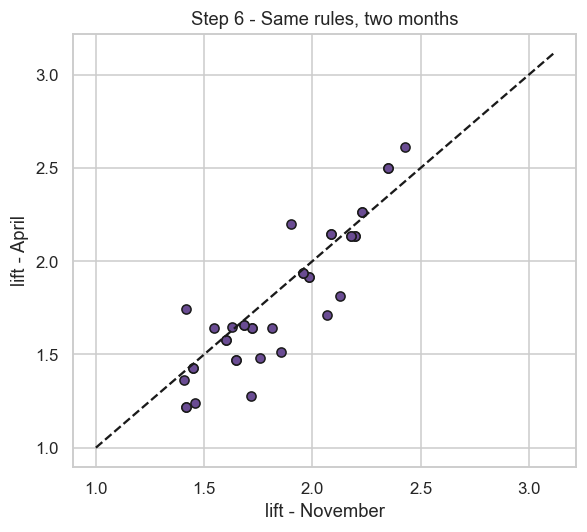

In [60]:
a = r_nov[(r_nov.n_ante == 1) & (r_nov.n_cons == 1)].set_index("rule")
b = r_apr[(r_apr.n_ante == 1) & (r_apr.n_cons == 1)].set_index("rule")
both = a.index.intersection(b.index)
only_nov, only_apr = a.index.difference(b.index), b.index.difference(a.index)
mm = pd.DataFrame({"lift_Nov": a.loc[both, "lift"], "lift_Apr": b.loc[both, "lift"],
                   "confidence_Nov": a.loc[both, "confidence"], "confidence_Apr": b.loc[both, "confidence"]})
mm["lift_change_%"] = (mm.lift_Apr / mm.lift_Nov - 1) * 100
print(f"One-to-one rules: {len(a)} in Nov, {len(b)} in Apr -> {len(both)} in BOTH ({len(both)/len(a.index.union(b.index)):.0%} of all distinct rules)")
print(f"Only in Nov: {len(only_nov)} | Only in Apr: {len(only_apr)}")
print(f"Mean absolute lift change between the months for shared rules: {mm['lift_change_%'].abs().mean():.1f}%")
mm.sort_values("lift_Nov", ascending=False).round(3).to_csv("outputs/08_month_stability_nov_vs_apr.csv")
if len(only_nov) + len(only_apr):
    display(pd.concat([a.loc[only_nov, ["confidence", "lift"]].assign(only_in="Nov"), b.loc[only_apr, ["confidence", "lift"]].assign(only_in="Apr")]).round(3))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(mm.lift_Nov, mm.lift_Apr, color="#6a4c93", edgecolor="k"); lim = [1, mm[["lift_Nov", "lift_Apr"]].max().max() + .5]
ax.plot(lim, lim, "k--"); ax.set_xlabel("lift - November"); ax.set_ylabel("lift - April"); ax.set_title("Step 6 - Same rules, two months")
plt.tight_layout(); plt.savefig("outputs/08b_month_stability.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation (Step 6):** Use the computed April-versus-November comparison above. Report each month's basket count, the number of shared rules, and how lift changes. These month-level results may be noisier because each month contains fewer baskets than a six-month period.

## 9. Do Patterns Differ by Event Type? (segment view)

Different events create different needs. Mining rules per event type shows *where* to deploy each cross-sell.

In [61]:
seg_rows = []
for ev in ["Wedding", "Mehndi", "Baraat", "Walima", "Nikkah", "Engagement"]:
    d = df[df["Event_Type"] == ev]
    r = mine_rules(make_onehot(d), min_support=0.03, min_conf=0.5, min_lift=1.5)
    r = r[(r.n_ante == 1) & (r.n_cons == 1)].head(3)
    for _, row in r.iterrows():
        seg_rows.append({"Event_Type": ev, "Baskets": d["Transaction_ID"].nunique(), "Rule": row["rule"],
                         "Support": row["support"], "Confidence": row["confidence"], "Lift": row["lift"]})
pd.DataFrame(seg_rows)

,Event_Type,Baskets,Rule,Support,Confidence,Lift
0,Wedding,1847,Dessert Table → Wedding Cake,0.119,0.726,2.488
1,Wedding,1847,Mehndi Artist → Bridal Makeup,0.210,0.739,2.321
2,Wedding,1847,Bridal Makeup → Mehndi Artist,0.210,0.660,2.321
3,Mehndi,1293,Dessert Table → Wedding Cake,0.101,0.722,2.788
4,Mehndi,1293,Bridal Dress Rental → Bridal Makeup,0.077,0.664,2.611
5,Mehndi,1293,Wedding Cake → Catering,0.169,0.654,2.335
6,Baraat,944,Dessert Table → Wedding Cake,0.113,0.759,2.683
7,Baraat,944,Catering → Wedding Cake,0.178,0.644,2.276
8,Baraat,944,Wedding Cake → Catering,0.178,0.629,2.276
9,Walima,1300,Bridal Dress Rental → Bridal Makeup,0.088,0.777,2.694


## 10. Selecting Actionable Cross-Selling Bundles — Step 7

Business criteria used to shortlist rules (all must hold):

1. **Validated** – lift > 1.2 in **both** periods
2. **One service → one service** – simple for a sales agent to apply
3. **Sensible sales direction** – the recommendation goes from the higher-ticket service A to the cheaper add-on B (e.g. Catering → Wedding Cake, not the reverse), because a customer who already committed to a big service is easiest to upsell
4. **Meaningful potential** – ranked by the *estimated revenue* the recommendation could generate (number of customers who have A but not B × average price of B)

For every pair (e.g. Photography ↔ Videography) only **one direction** is kept.

In [62]:
# ---- candidate directed rules A -> B validated in both periods ----
cand = cmp_1to1[cmp_1to1.validated].copy()
cand["A"], cand["B"] = cand["antecedent"], cand["consequent"]

# Sales direction: pitch the cheaper add-on (B) to customers who already booked the bigger-ticket service (A).
avg_line = service_table["Avg_Line_Revenue_PKR"]
cand = cand[cand["A"].map(avg_line) >= cand["B"].map(avg_line)].copy()

# ---- revenue potential on the full 2025 data ----
has = basket_all
total_baskets = len(has)
avg_b_rev, eligible, existing_conv = [], [], []
line_rev = df.groupby(["Transaction_ID", "Service"])["Line_Revenue_PKR"].sum()

for _, r in cand.iterrows():
    A, B = r["A"], r["B"]
    elig_ids = has.index[has[A] & ~has[B]]
    eligible.append(len(elig_ids))
    existing_conv.append(has.loc[has[A], B].mean())
    # average revenue of B in baskets that already contain A (the realistic price level for that customer type)
    b_in_a = df[(df["Service"] == B) & df["Transaction_ID"].isin(has.index[has[A]])]["Line_Revenue_PKR"]
    avg_b_rev.append(b_in_a.mean())

cand["eligible_baskets"] = eligible
cand["avg_B_revenue_PKR"] = avg_b_rev
cand["current_conversion"] = existing_conv
cand["potential_revenue_10pct"] = cand["eligible_baskets"] * 0.10 * cand["avg_B_revenue_PKR"]

# keep the better direction for each pair
cand["pair"] = cand.apply(lambda r: " + ".join(sorted([r["A"], r["B"]])), axis=1)
best = (cand.sort_values("potential_revenue_10pct", ascending=False)
            .drop_duplicates("pair").reset_index(drop=True))

best[["rule", "support_main", "confidence_main", "lift_main", "confidence_val", "lift_val",
      "eligible_baskets", "avg_B_revenue_PKR", "potential_revenue_10pct"]]

,rule,support_main,confidence_main,lift_main,confidence_val,lift_val,eligible_baskets,avg_B_revenue_PKR,potential_revenue_10pct
0,Decoration → Stage & Backdrop,0.132,0.378,2.241,0.399,2.211,1586,"181,322.134","28,757,690.514"
1,Floral Design → Venue Styling,0.118,0.395,1.710,0.403,1.703,1335,"155,454.340","20,753,154.453"
2,Decoration → Venue Styling,0.176,0.505,2.184,0.532,2.251,1248,"156,857.037","19,575,758.222"
3,Lighting → DJ,0.155,0.338,1.530,0.326,1.539,2284,"83,350.707","19,037,301.413"
4,Decoration → Floral Design,0.206,0.590,1.981,0.588,1.991,1069,"165,778.940","17,721,768.738"
5,Catering → Invitation Cards,0.121,0.364,1.695,0.391,1.720,1585,"78,656.573","12,467,066.900"
6,Stage & Backdrop → Venue Styling,0.078,0.462,1.998,0.459,1.943,709,"156,028.099","11,062,392.231"
7,Photography → Videography,0.285,0.729,1.956,0.726,2.013,795,"138,716.509","11,027,962.500"
8,Stage & Backdrop → Floral Design,0.092,0.545,1.831,0.491,1.662,638,"163,714.497","10,444,984.911"
9,Floral Design → Lighting,0.181,0.607,1.324,0.626,1.382,850,"110,168.367","9,364,311.224"


In [63]:
# ---- Final shortlist: top bundles (at least 5) ----
N_BUNDLES = 10
final = best.head(N_BUNDLES).copy()

actions = {
    ("Photography", "Videography"):        "When a customer books Photography, offer the Videography package (photo + video combo).",
    ("Videography", "Photography"):        "When a customer books Videography, offer the Photography package.",
    ("Decoration", "Lighting"):            "Attach a Lighting upgrade to every Decoration quote (e.g. stage + ambient lighting bundle).",
    ("Lighting", "Decoration"):            "When Lighting is requested, propose a matching Decoration package.",
    ("Decoration", "Floral Design"):       "Include a Floral Design add-on (entrance, stage, table centrepieces) in Decoration quotes.",
    ("Floral Design", "Decoration"):       "When Floral Design is requested, propose a matching Decoration package.",
    ("Decoration", "Venue Styling"):       "Offer Venue Styling (entrance, seating, backdrop) as a package with Decoration.",
    ("Venue Styling", "Decoration"):       "When Venue Styling is booked, add the Decoration package.",
    ("Catering", "Wedding Cake"):          "When a customer books Catering, offer a Wedding Cake as a dessert add-on.",
    ("Wedding Cake", "Catering"):          "When a Wedding Cake is booked, offer the Catering package.",
    ("Bridal Makeup", "Mehndi Artist"):    "Offer a Bridal Makeup + Mehndi Artist bride package.",
    ("Mehndi Artist", "Bridal Makeup"):    "When a Mehndi Artist is booked, offer Bridal Makeup (bride package).",
    ("DJ", "Lighting"):                    "Add DJ-floor Lighting to every DJ booking.",
    ("Lighting", "DJ"):                    "When Lighting is requested, offer a DJ + dance-floor package.",
    ("Videography", "Drone Coverage"):     "Offer Drone Coverage as an upgrade to every Videography package.",
    ("Drone Coverage", "Videography"):     "When Drone Coverage is booked, add Videography.",
    ("DJ", "Photo Booth"):                 "Offer a Photo Booth together with the DJ package.",
    ("Photo Booth", "DJ"):                 "When a Photo Booth is booked, offer a DJ package.",
    ("DJ", "Entry Effects"):               "Offer Entry Effects (cold sparks, smoke) with the DJ package.",
    ("Entry Effects", "DJ"):               "When Entry Effects are booked, add a DJ package.",
    ("Bridal Makeup", "Bridal Car Rental"):"Offer Bridal Car Rental in the bridal makeup package.",
    ("Bridal Car Rental", "Bridal Makeup"):"When a Bridal Car is booked, offer Bridal Makeup.",
    ("Invitation Cards", "Wedding Favors"):"Offer Wedding Favors with Invitation Card orders.",
    ("Wedding Favors", "Invitation Cards"):"When Wedding Favors are ordered, offer Invitation Cards.",
    ("Photography", "Bridal Makeup"):      "Offer a bridal makeup + photography combo.",
    ("Bridal Makeup", "Photography"):       "When Bridal Makeup is booked, offer the Photography package.",
    ("Wedding Cake", "Floral Design"):     "Offer Floral Design (cake table) with the Wedding Cake.",
    ("Floral Design", "Wedding Cake"):     "When Floral Design is booked, offer a Wedding Cake.",
}
final["Recommended_Action"] = [actions.get((r.A, r.B), f"When a customer books {r.A}, recommend {r.B}.") for r in final.itertuples()]
final.insert(0, "Bundle_No", range(1, len(final) + 1))
final["Priority"] = np.where(final["Bundle_No"] <= 5, "Top 5 - launch first", "Second wave")

show = final[["Bundle_No", "rule", "support_main", "confidence_main", "lift_main", "confidence_val", "lift_val", "Recommended_Action"]]
show.rename(columns={"rule": "Recommendation (A → B)", "support_main": "Support", "confidence_main": "Confidence",
                     "lift_main": "Lift", "confidence_val": "Conf (validation)", "lift_val": "Lift (validation)"})

,Bundle_No,Recommendation (A → B),Support,Confidence,Lift,Conf (validation),Lift (validation),Recommended_Action
0,1,Decoration → Stage & Backdrop,0.132,0.378,2.241,0.399,2.211,"When a customer books Decoration, recommend St..."
1,2,Floral Design → Venue Styling,0.118,0.395,1.710,0.403,1.703,"When a customer books Floral Design, recommend..."
2,3,Decoration → Venue Styling,0.176,0.505,2.184,0.532,2.251,"Offer Venue Styling (entrance, seating, backdr..."
3,4,Lighting → DJ,0.155,0.338,1.530,0.326,1.539,"When Lighting is requested, offer a DJ + dance..."
4,5,Decoration → Floral Design,0.206,0.590,1.981,0.588,1.991,"Include a Floral Design add-on (entrance, stag..."
5,6,Catering → Invitation Cards,0.121,0.364,1.695,0.391,1.720,"When a customer books Catering, recommend Invi..."
6,7,Stage & Backdrop → Venue Styling,0.078,0.462,1.998,0.459,1.943,"When a customer books Stage & Backdrop, recomm..."
7,8,Photography → Videography,0.285,0.729,1.956,0.726,2.013,"When a customer books Photography, offer the V..."
8,9,Stage & Backdrop → Floral Design,0.092,0.545,1.831,0.491,1.662,"When a customer books Stage & Backdrop, recomm..."
9,10,Floral Design → Lighting,0.181,0.607,1.324,0.626,1.382,"When a customer books Floral Design, recommend..."


### How to read a bundle (example)
For a rule such as **Photography → Videography**: *confidence* is the share of Photography baskets that also contain Videography, *lift* shows how many times more often they are bought together than chance alone would predict, and the *validation* columns show the same rule on the Jul–Dec baskets.

## 11. Revenue Impact of the Recommended Bundles — Step 7

**Method (per bundle A → B, using all 7,500 baskets of 2025):**

- *Eligible baskets* = baskets that contain A but **not** B (the customers we can still pitch B to)
- *Average B revenue* = mean line revenue of B in baskets that contain A (realistic price for that customer type)
- *Incremental revenue* = eligible baskets × **uplift conversion rate** × average B revenue × **(1 − bundle discount of 10 %)**
- The **top 5 bundles by revenue** are the priority bundles proposed to the client; bundles 6-10 are a second wave.
- Not modelled: margin, cannibalisation of existing sales, and overlap between bundles (totals are an upper bound).

The uplift conversion rate is an **assumption** (the share of eligible customers who accept the recommendation). Three scenarios are shown: **conservative 5 %**, **moderate 10 %**, **optimistic 20 %**. Results are only as realistic as these assumptions and the simulated data.

In [64]:
SCENARIOS = {"Conservative (5%)": 0.05, "Moderate (10%)": 0.10, "Optimistic (20%)": 0.20}

rev = final[["Bundle_No", "rule", "eligible_baskets", "avg_B_revenue_PKR", "current_conversion"]].copy()
for name, rate in SCENARIOS.items():
    rev[f"{name} – extra baskets"] = rev["eligible_baskets"] * rate
    rev[f"{name} – revenue PKR"] = rev["eligible_baskets"] * rate * rev["avg_B_revenue_PKR"] * (1 - DISCOUNT)   # bundle discount applied

total_rev = df["Line_Revenue_PKR"].sum()
rev_display = rev[["Bundle_No", "rule", "eligible_baskets", "avg_B_revenue_PKR"] +
                  [f"{n} – revenue PKR" for n in SCENARIOS]].copy()
rev_display

,Bundle_No,rule,eligible_baskets,avg_B_revenue_PKR,Conservative (5%) – revenue PKR,Moderate (10%) – revenue PKR,Optimistic (20%) – revenue PKR
0,1,Decoration → Stage & Backdrop,1586,"181,322.134","12,940,960.731","25,881,921.462","51,763,842.925"
1,2,Floral Design → Venue Styling,1335,"155,454.340","9,338,919.504","18,677,839.008","37,355,678.016"
2,3,Decoration → Venue Styling,1248,"156,857.037","8,809,091.200","17,618,182.400","35,236,364.800"
3,4,Lighting → DJ,2284,"83,350.707","8,566,785.636","17,133,571.272","34,267,142.544"
4,5,Decoration → Floral Design,1069,"165,778.940","7,974,795.932","15,949,591.864","31,899,183.728"
5,6,Catering → Invitation Cards,1585,"78,656.573","5,610,180.105","11,220,360.210","22,440,720.419"
6,7,Stage & Backdrop → Venue Styling,709,"156,028.099","4,978,076.504","9,956,153.008","19,912,306.017"
7,8,Photography → Videography,795,"138,716.509","4,962,583.125","9,925,166.250","19,850,332.500"
8,9,Stage & Backdrop → Floral Design,638,"163,714.497","4,700,243.210","9,400,486.420","18,800,972.840"
9,10,Floral Design → Lighting,850,"110,168.367","4,213,940.051","8,427,880.102","16,855,760.204"


In [65]:
totals = pd.DataFrame({
    "Scenario": list(SCENARIOS),
    "Uplift rate": list(SCENARIOS.values()),
    "Incremental revenue (PKR)": [rev[f"{n} – revenue PKR"].sum() for n in SCENARIOS],
})
totals["% of 2025 revenue"] = totals["Incremental revenue (PKR)"] / total_rev * 100
print(f"2025 simulated revenue: PKR {total_rev:,.0f}   |   Average basket: PKR {basket_value.mean():,.0f}\n")
print("Note: bundle revenues overlap (one basket may receive several recommendations), so the total is an upper-bound estimate.")
totals

2025 simulated revenue: PKR 6,622,502,500   |   Average basket: PKR 883,000

Note: bundle revenues overlap (one basket may receive several recommendations), so the total is an upper-bound estimate.


,Scenario,Uplift rate,Incremental revenue (PKR),% of 2025 revenue
0,Conservative (5%),0.050,"72,095,575.998",1.089
1,Moderate (10%),0.100,"144,191,151.996",2.177
2,Optimistic (20%),0.200,"288,382,303.993",4.355


### 11.1 Step 7 — The five priority bundles and the stated assumptions

In [66]:
assump = pd.DataFrame({"Assumption": ["Conversion of eligible customers (scenarios)", "Bundle discount on the add-on", "Eligible customers",
                                      "Revenue price used", "Not modelled"],
                       "Value": ["5 % / 10 % / 20 % (not measured - to be replaced by A/B-test results)", f"{DISCOUNT:.0%}",
                                 "Baskets with service A but without service B in 2025 (7,500 baskets)", "Mean line revenue of B in baskets that already contain A",
                                 "Margin, cannibalisation, overlap between bundles, quantity effects"]})
display(assump)
top5 = final[["Bundle_No", "rule", "Recommended_Action", "confidence_main", "lift_main", "confidence_val", "lift_val"]].head(5).merge(
       rev[["Bundle_No", "eligible_baskets", "avg_B_revenue_PKR"] + [f"{n} – revenue PKR" for n in SCENARIOS]], on="Bundle_No")
top5.round(3).to_csv("outputs/11_cross_sell_action_plan_top5.csv", index=False)
final.round(3).drop(columns=["antecedents", "consequents"], errors="ignore").to_csv("outputs/10_all_10_bundles.csv", index=False)
rev.round(1).to_csv("outputs/11_revenue_estimates_all_bundles.csv", index=False)
print("Top-5 incremental revenue (PKR million, after 10% discount):")
print({n: round(top5[f"{n} – revenue PKR"].sum() / 1e6, 1) for n in SCENARIOS})
top5.round(2)

,Assumption,Value
0,Conversion of eligible customers (scenarios),5 % / 10 % / 20 % (not measured - to be replac...
1,Bundle discount on the add-on,10%
2,Eligible customers,Baskets with service A but without service B i...
3,Revenue price used,Mean line revenue of B in baskets that already...
4,Not modelled,"Margin, cannibalisation, overlap between bundl..."


Top-5 incremental revenue (PKR million, after 10% discount):
{'Conservative (5%)': np.float64(47.6), 'Moderate (10%)': np.float64(95.3), 'Optimistic (20%)': np.float64(190.5)}


,Bundle_No,rule,Recommended_Action,confidence_main,lift_main,confidence_val,lift_val,eligible_baskets,avg_B_revenue_PKR,Conservative (5%) – revenue PKR,Moderate (10%) – revenue PKR,Optimistic (20%) – revenue PKR
0,1,Decoration → Stage & Backdrop,"When a customer books Decoration, recommend St...",0.380,2.240,0.400,2.210,1586,"181,322.130","12,940,960.730","25,881,921.460","51,763,842.920"
1,2,Floral Design → Venue Styling,"When a customer books Floral Design, recommend...",0.400,1.710,0.400,1.700,1335,"155,454.340","9,338,919.500","18,677,839.010","37,355,678.020"
2,3,Decoration → Venue Styling,"Offer Venue Styling (entrance, seating, backdr...",0.500,2.180,0.530,2.250,1248,"156,857.040","8,809,091.200","17,618,182.400","35,236,364.800"
3,4,Lighting → DJ,"When Lighting is requested, offer a DJ + dance...",0.340,1.530,0.330,1.540,2284,"83,350.710","8,566,785.640","17,133,571.270","34,267,142.540"
4,5,Decoration → Floral Design,"Include a Floral Design add-on (entrance, stag...",0.590,1.980,0.590,1.990,1069,"165,778.940","7,974,795.930","15,949,591.860","31,899,183.730"


**Proposal to the client (Step 7):** Use the top five rows and revenue scenarios calculated in the cells above. State the computed estimates and repeat the assumptions: conversion rates are scenarios, not measured results; a 10% add-on discount is assumed; and overlapping bundles may double-count customers. Do not use any figures from a prior run unless the current output confirms them.

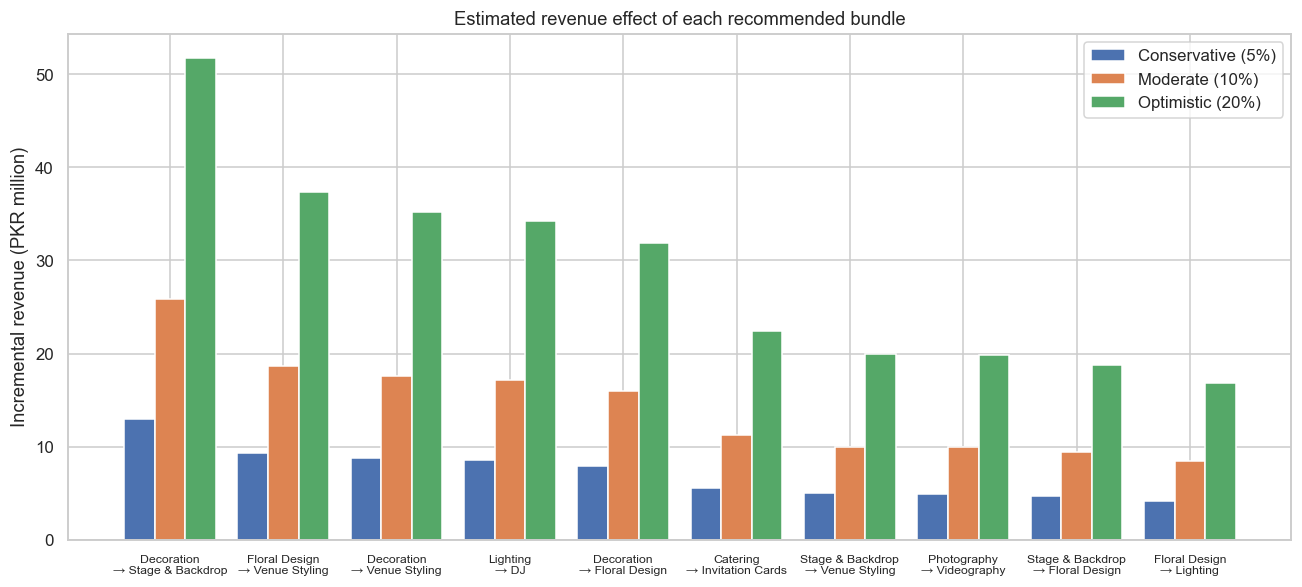

In [67]:
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(rev)); w = 0.27
for i, (name, _) in enumerate(SCENARIOS.items()):
    ax.bar(x + (i - 1) * w, rev[f"{name} – revenue PKR"] / 1e6, w, label=name)
ax.set_xticks(x); ax.set_xticklabels(rev["rule"].str.replace("  →  ", "\n→ "), fontsize=8)
ax.set_ylabel("Incremental revenue (PKR million)"); ax.set_title("Estimated revenue effect of each recommended bundle")
ax.legend(); plt.tight_layout(); plt.savefig("outputs/11_revenue_by_bundle.png", dpi=150, bbox_inches="tight"); plt.show()

## 12. Sensitivity: how robust are the rules to the thresholds? (extends Step 4)

In [68]:
rows = []
for ms in [0.01, 0.02, 0.03, 0.05]:
    for ml in [1.2, 1.5, 2.0]:
        r = mine_rules(basket_main, min_support=ms, min_conf=MIN_CONF, min_lift=ml)
        rows.append({"min_support": ms, "min_lift": ml, "rules": len(r)})
pd.DataFrame(rows).pivot(index="min_support", columns="min_lift", values="rules")

min_lift,1.200,1.500,2.000
min_support,,,
0.010,408,397,357
0.020,218,210,177
0.030,164,157,124
0.050,104,98,68


## 13. Key Findings (computed from the results above)

In [69]:
n_val = int(cmp["validated"].sum())
print(f"• {df['Transaction_ID'].nunique():,} unique baskets, {df['Service'].nunique()} services, average {basket_size.mean():.1f} services per basket.")
print(f"• Main period (Jan–Jun): {len(rules_main)} rules with lift > {MIN_LIFT}; {n_val} ({n_val/len(cmp):.0%}) were validated in Jul–Dec.")
print(f"• {len(final)} actionable bundles selected (all validated in both periods):\n")
for r in final.itertuples():
    print(f"  {r.Bundle_No}. {r.rule.replace('  →  ', ' → ')}: support {r.support_main:.1%}, confidence {r.confidence_main:.0%}, lift {r.lift_main:.2f} "
          f"(validation: confidence {r.confidence_val:.0%}, lift {r.lift_val:.2f})")
print(f"• Step 5: {len(near_certain)} near-certain (confidence >= {TRIVIAL_CONF:.0%}) and {len(redundant)} redundant multi-service rules were removed as trivial.")
print(f"• Step 8 (frozen holdout): {strict.holds.sum()} of {len(strict)} Jan-Jun rules keep lift > {MIN_LIFT} in Jul-Dec; top-10 rules: {one.head(10).holds.sum()} of 10.")
print(f"• Step 6: {len(both)} one-to-one rules appear in both November and April.")
print(f"\n• Estimated incremental revenue if the bundles are pitched to eligible customers: "
      f"PKR {totals.iloc[0,2]/1e6:,.1f}M (5%), PKR {totals.iloc[1,2]/1e6:,.1f}M (10%), PKR {totals.iloc[2,2]/1e6:,.1f}M (20%).")

• 7,500 unique baskets, 20 services, average 4.8 services per basket.
• Main period (Jan–Jun): 218 rules with lift > 1.2; 190 (87%) were validated in Jul–Dec.
• 10 actionable bundles selected (all validated in both periods):

  1. Decoration → Stage & Backdrop: support 13.2%, confidence 38%, lift 2.24 (validation: confidence 40%, lift 2.21)
  2. Floral Design → Venue Styling: support 11.8%, confidence 40%, lift 1.71 (validation: confidence 40%, lift 1.70)
  3. Decoration → Venue Styling: support 17.6%, confidence 50%, lift 2.18 (validation: confidence 53%, lift 2.25)
  4. Lighting → DJ: support 15.5%, confidence 34%, lift 1.53 (validation: confidence 33%, lift 1.54)
  5. Decoration → Floral Design: support 20.6%, confidence 59%, lift 1.98 (validation: confidence 59%, lift 1.99)
  6. Catering → Invitation Cards: support 12.1%, confidence 36%, lift 1.69 (validation: confidence 39%, lift 1.72)
  7. Stage & Backdrop → Venue Styling: support 7.8%, confidence 46%, lift 2.00 (validation: conf

In [70]:

import os

os.makedirs("outputs", exist_ok=True)

# Save all filtered association rules
rules_main.to_csv("outputs/association_rules.csv", index=False)

# Save only one-service-to-one-service rules
rules_main_1to1.to_csv("outputs/association_rules_one_to_one.csv", index=False)

print("Association rules exported successfully!")
print("Total filtered rules:", len(rules_main))
print("One-to-one rules:", len(rules_main_1to1))


Association rules exported successfully!
Total filtered rules: 218
One-to-one rules: 44
